The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
<class 'pandas.DataFrame'>
RangeIndex: 56 entries, 0 to 55
Data columns (total 9 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   epoch                    56 non-null     int64  
 1   train_per_step_loss      56 non-null     object 
 2   train_variance_loss      56 non-null     float64
 3   train_grad_norm          56 non-null     float64
 4   test_mse_losses          56 non-null     object 
 5   test_r2_scores           56 non-null     object 
 6   test_copy_z_mse_losses   56 non-null     object 
 7   test_z_hat_variances     56 non-null     object 
 8   test_z_target_variances  56 non-null     object 
dtypes: float64(2), int64(1), object(6)
memory usage: 4.1+ KB
None
tensor(1.1783)
tensor(1.1782)


<Axes: title={'center': 'Law Delta'}, xlabel='step'>

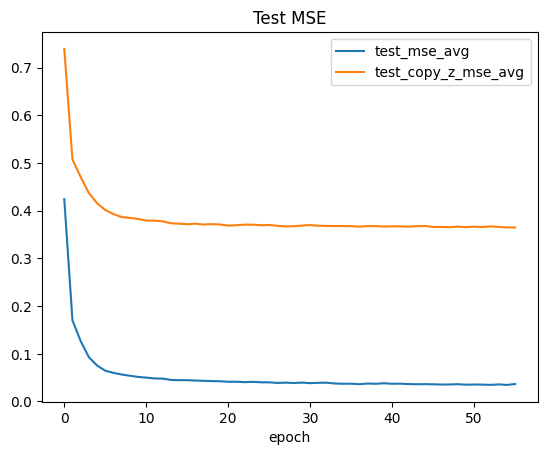

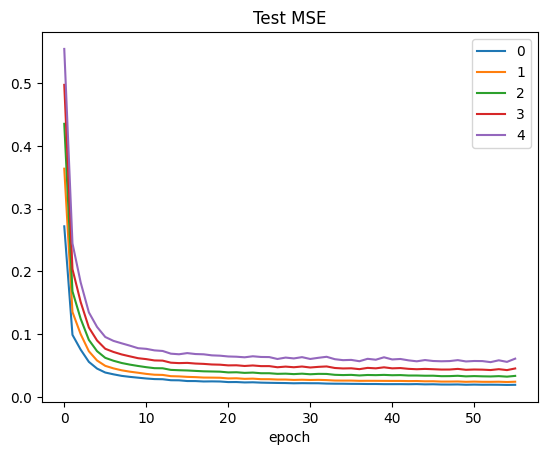

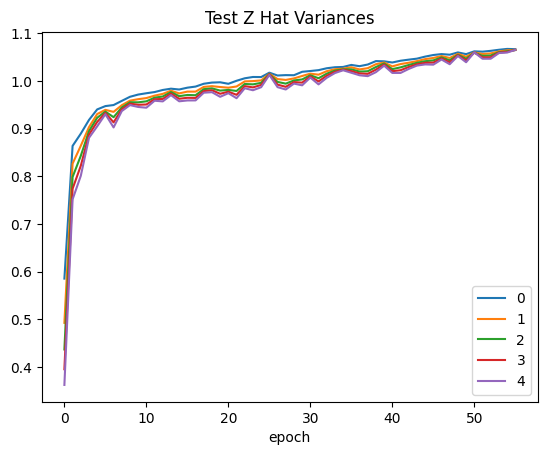

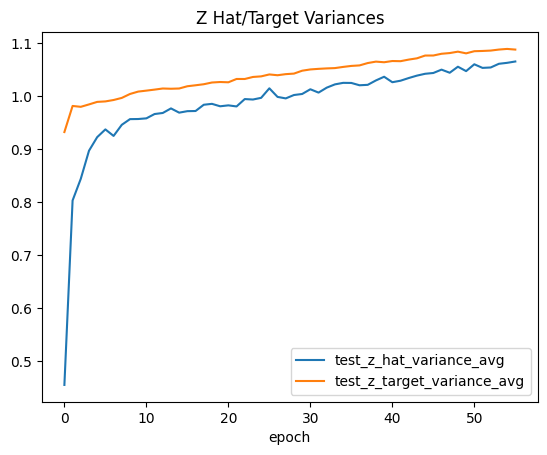

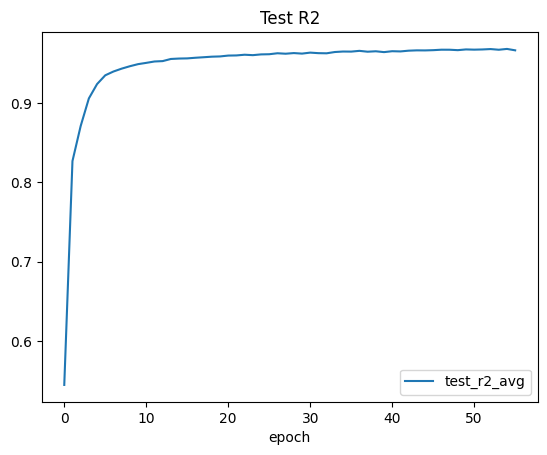

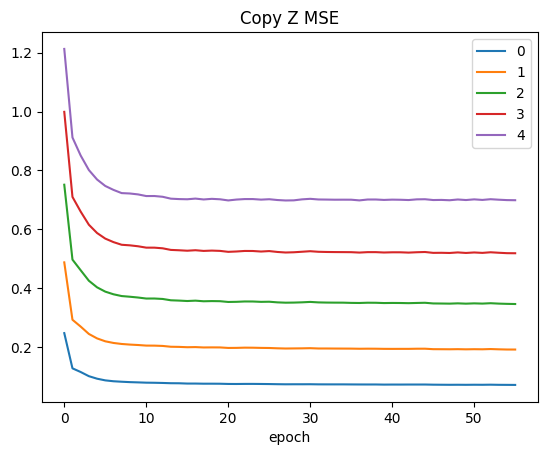

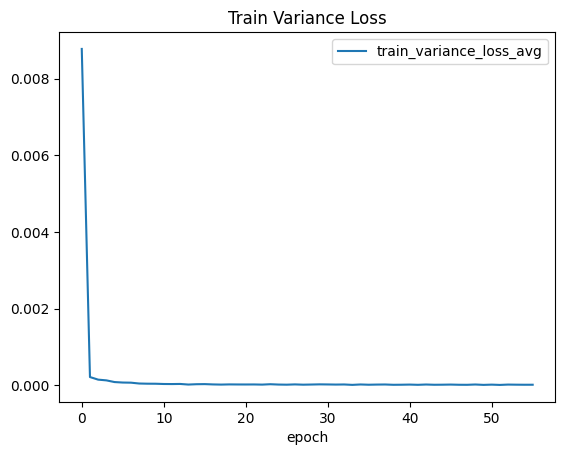

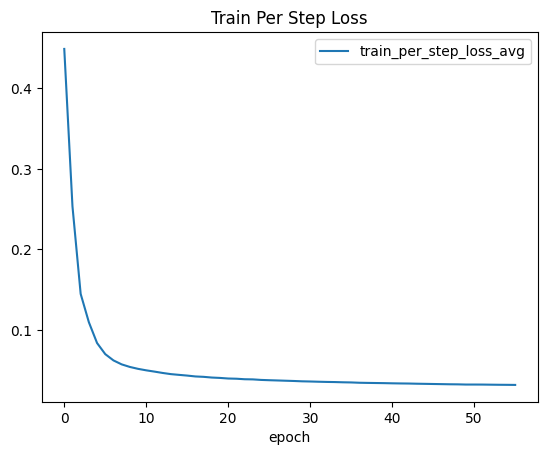

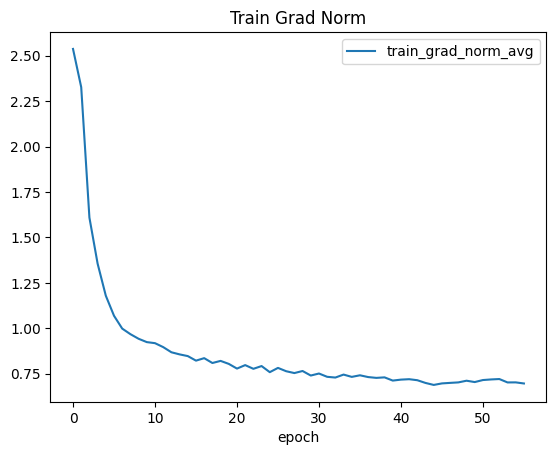

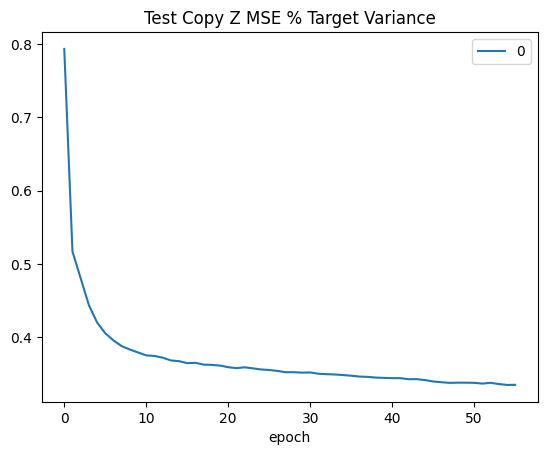

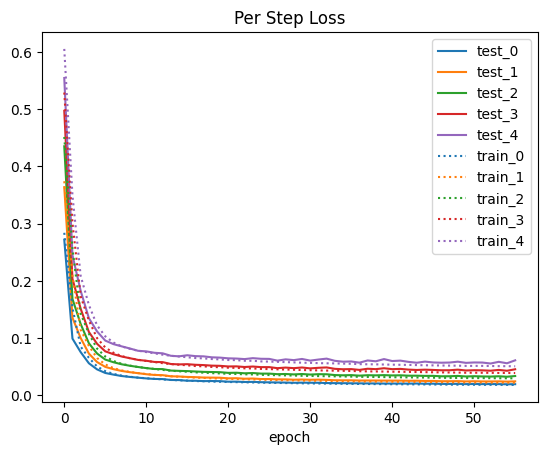

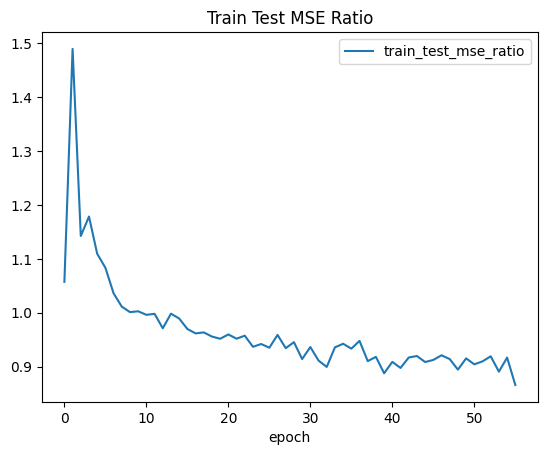

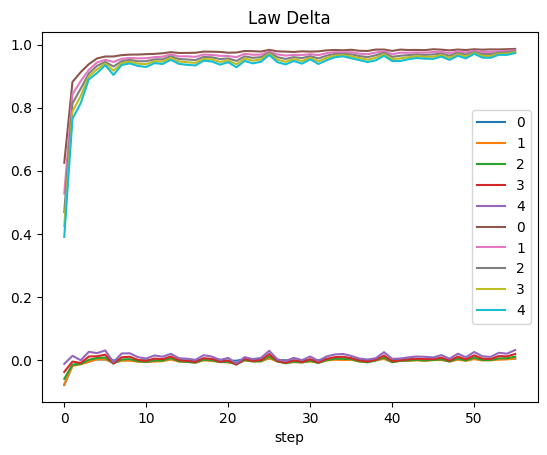

In [19]:
%load_ext autoreload
%autoreload 2

import torch
import pandas as pd
from wm.env.paths import ROLLOUT_LOG_PATH, ROLLOUT_BEST_CHECKPOINT_PATH
import numpy as np

results = pd.read_json(ROLLOUT_LOG_PATH, lines=True)

df = pd.DataFrame(results)

print(df.info())

checkpoint = torch.load(ROLLOUT_BEST_CHECKPOINT_PATH, weights_only=False, map_location="cpu")
gamma = checkpoint["encoder"]["14.weight"]
target_gamma = checkpoint["encoder_target"]["14.weight"]

print(gamma.mean())
print(target_gamma.mean())

df["test_mse_avg"] = df["test_mse_losses"].map(np.mean)
df["test_r2_avg"] = df["test_r2_scores"].map(np.mean)
df["test_copy_z_mse_avg"] = df["test_copy_z_mse_losses"].map(np.mean)
df["test_z_hat_variance_avg"] = df["test_z_hat_variances"].map(np.mean)
df["test_z_target_variance_avg"] = df["test_z_target_variances"].map(np.mean)
df["train_variance_loss_avg"] = df["train_variance_loss"].map(np.mean)
df["train_per_step_loss_avg"] = df["train_per_step_loss"].map(np.mean)
df["train_grad_norm_avg"] = df["train_grad_norm"].map(np.mean)

df.plot(
    x="epoch",
    y=[
        "test_mse_avg",
        "test_copy_z_mse_avg",
    ],
    kind="line",
    title="Test MSE",
)
df["test_mse_losses"].apply(pd.Series).set_index(df["epoch"]).plot(kind="line", title="Test MSE")
df["test_z_hat_variances"].apply(pd.Series).set_index(df["epoch"]).plot(
    kind="line", title="Test Z Hat Variances"
)
df.plot(
    x="epoch",
    y=[
        "test_z_hat_variance_avg",
        "test_z_target_variance_avg",
    ],
    kind="line",
    title="Z Hat/Target Variances",
)

df.plot(x="epoch", y="test_r2_avg", kind="line", title="Test R2")
df["test_copy_z_mse_losses"].apply(pd.Series).set_index(df["epoch"]).plot(
    kind="line", title="Copy Z MSE"
)
df.plot(x="epoch", y="train_variance_loss_avg", kind="line", title="Train Variance Loss")
df.plot(x="epoch", y="train_per_step_loss_avg", kind="line", title="Train Per Step Loss")
df.plot(x="epoch", y="train_grad_norm_avg", kind="line", title="Train Grad Norm")

df["copy_z_mse_over_target_variance"] = df["test_copy_z_mse_avg"] / df["test_z_target_variance_avg"]
df["copy_z_mse_over_target_variance"].apply(pd.Series).set_index(df["epoch"]).plot(
    kind="line", title="Test Copy Z MSE % Target Variance"
)
df["train_test_mse_ratio"] = df["train_per_step_loss"].apply(np.mean) / df["test_mse_losses"].apply(
    np.mean
)
per_step = pd.concat(
    [
        df["test_mse_losses"].apply(pd.Series).add_prefix("test_"),
        df["train_per_step_loss"].apply(pd.Series).add_prefix("train_"),
    ],
    axis=1,
).set_index(df["epoch"])
n_steps = per_step.filter(like="test_").shape[1]
per_step.plot(
    kind="line",
    title="Per Step Loss",
    color=[f"C{i}" for i in range(n_steps)] * 2,
    style=["-"] * n_steps + [":"] * n_steps,
)
df.plot(x="epoch", y="train_test_mse_ratio", kind="line", title="Train Test MSE Ratio")

var_z_hat = df["test_z_hat_variances"].apply(pd.Series).set_index(df["epoch"])
z_hat_mse = df["test_mse_losses"].apply(pd.Series).set_index(df["epoch"])
z_t_var = df["test_z_target_variances"].apply(pd.Series).set_index(df["epoch"])

# if this is positive it means
law_total_var = var_z_hat + z_hat_mse

law_delta = law_total_var - z_t_var

delta_ratio = law_delta / z_t_var

var_ratio = var_z_hat / z_t_var

# var ratio -> 1 AND delta ratio -> 0.2 @ step 4
# this must mean MSE continues to rise at the same time as MSE
# the model is overconfident

law_per_step = pd.concat(
    [
        law_delta.apply(pd.Series),
        var_ratio.apply(pd.Series),
    ],
    axis=1,
)
law_per_step.index.name = "step"
law_per_step.plot(kind="line", title="Law Delta")


In [20]:
from wm.env.paths import (
    ROLLOUT_BEST_CHECKPOINT_PATH,
    ROLLOUT_BEST_PROBE_CHECKPOINT_PATH,
    ROLLOUT_BEST_PROBE_RIDGE_CHECKPOINT_PATH,
)
import matplotlib.pyplot as plt
import numpy as np

from wm.probe.runner import (
    NAMES,
    bounce_splits,
    collect_eval,
    load_eval,
    test_loader,
)
from wm.nets.jepa import Nets
import torch

nets = Nets()

device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")

nets, beta, bias, probe_gt_mean, probe_gt_std = load_eval(
    nets,
    jepa_checkpoint_path=ROLLOUT_BEST_CHECKPOINT_PATH,
    probe_checkpoint_path=ROLLOUT_BEST_PROBE_CHECKPOINT_PATH,
    probe_ridge_checkpoint_path=ROLLOUT_BEST_PROBE_RIDGE_CHECKPOINT_PATH,
    device=device,
)

loader = test_loader()
ev = collect_eval(nets, beta, bias, probe_gt_mean, probe_gt_std, loader, device)
splits = bounce_splits(ev["bounce"])
print({k: v.shape for k, v in ev.items()})

Eval probe: 100%|██████████| 149/149 [00:07<00:00, 18.64it/s]

{'z': (19000, 32), 'z_hat': (19000, 32), 'z_target': (19000, 32), 'z_decoded': (19000, 4), 'z_decoded_t_minus_1': (19000, 4), 'z_hat_decoded': (19000, 4), 'z_target_decoded': (19000, 4), 'ridge_decoded': (19000, 4), 'gt_t': (19000, 4), 'gt_tminus1': (19000, 4), 'gt_tp1': (19000, 4), 'bounce': (19000,), 'action': (19000, 2), 't': (19000,)}


In [21]:
from wm.probe.runner import print_repr_table

print("---t---")
print_repr_table({"mlp": ev["z_decoded"], "ridge": ev["ridge_decoded"]}, ev["gt_t"], probe_gt_std)

print("---t-1---")
print_repr_table({"mlp": ev["z_decoded_t_minus_1"]}, ev["gt_tminus1"], probe_gt_std)

z, gts = ev["z"], ev["gt_t"]
for j, name in enumerate(NAMES):
    corrs = [np.corrcoef(z[:, k], gts[:, j])[0, 1] for k in range(z.shape[1])]
    print(f"{name} max |corr| with any z dim: {np.nanmax(np.abs(corrs)):.4f}")

---t---
dim  probe                 R2         MSE  Pixel RMSE
-----------------------------------------------------
X    mlp               0.9996      0.0004      0.6963
     ridge             0.9899      0.0103      3.4466

Y    mlp               0.9996      0.0004      0.7060
     ridge             0.9874      0.0125      3.7967

VX   mlp               0.9148      0.0850      1.0789
     ridge             0.8609      0.1388      1.3784

VY   mlp               0.9195      0.0793      1.0355
     ridge             0.8529      0.1448      1.3994

---t-1---
dim  probe                 R2         MSE  Pixel RMSE
-----------------------------------------------------
X    mlp               0.9994      0.0006      0.8240

Y    mlp               0.9994      0.0006      0.8145

VX   mlp               0.8304      0.1521      1.4431

VY   mlp               0.8247      0.1561      1.4532

X max |corr| with any z dim: 0.8914
Y max |corr| with any z dim: 0.8500
VX max |corr| with any z dim: 0.3453
V

In [22]:
from wm.probe.runner import print_dynamics_table

print_dynamics_table(
    splits,
    ev["z_target_decoded"],
    ev["z_hat_decoded"],
    ev["gt_tp1"],
    probe_gt_std,
)

split         n  dim   tgt R2   hat R2      dR2  tgt MSE  hat MSE hat Pixel RMSE tgt Pixel RMSE
-----------------------------------------------------------------------------------------------
all       19000    X   0.9995   0.9985  -0.0010   0.0005   0.0015       1.3239       0.7553
all       19000    Y   0.9995   0.9985  -0.0010   0.0005   0.0015       1.3023       0.7736
all       19000   VX   0.9127   0.9239   0.0111   0.0956   0.0834       1.0684       1.1439
all       19000   VY   0.9152   0.9205   0.0054   0.0913   0.0855       1.0755       1.1112
-----------------------------------------------------------------------------------------------
bounce      927    X   0.9996   0.9977  -0.0019   0.0007   0.0044       2.2444       0.8966
bounce      927    Y   0.9996   0.9977  -0.0019   0.0008   0.0043       2.2339       0.9722
bounce      927   VX   0.3819   0.6785   0.2967   1.0750   0.5591       2.7667       3.8364
bounce      927   VY   0.4037   0.6997   0.2960   1.0722   0.5399   

In [23]:
from wm.probe.runner import rollout

zs, zts, holds, hold_decodeds, z_decodeds, gts = rollout(nets, device, probe_gt_mean, probe_gt_std)


Rollout: 100%|██████████| 100/100 [00:04<00:00, 24.97it/s]


In [24]:
from wm.probe.runner import calculate_per_dim_variance

var = calculate_per_dim_variance(zs)

var_df = pd.DataFrame(
    var,
    index=range(var.shape[0]),  # step
    columns=range(var.shape[1]),  # dim
)

var_df.index.name = "step"
var_df.style.format("{:.3f}").background_gradient(axis=None)


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30,31
step,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
0,1.206,1.013,0.951,1.011,1.201,1.193,1.014,1.027,1.001,0.924,0.958,1.701,1.174,1.175,1.102,1.052,0.899,0.908,1.059,0.967,1.131,0.961,1.096,0.900,1.106,0.957,0.909,0.933,0.912,1.045,1.088,1.035
1,1.214,0.994,0.941,1.001,1.191,1.189,1.016,1.040,0.978,0.937,0.957,1.702,1.167,1.190,1.092,1.065,0.902,0.905,1.052,0.964,1.136,0.956,1.099,0.889,1.094,0.958,0.909,0.931,0.927,1.053,1.071,1.032
2,1.213,0.991,0.937,1.000,1.191,1.192,0.999,1.048,0.962,0.945,0.951,1.724,1.161,1.187,1.075,1.068,0.898,0.909,1.053,0.954,1.142,0.966,1.106,0.884,1.074,0.956,0.925,0.930,0.941,1.076,1.064,1.040
3,1.212,0.981,0.938,1.012,1.188,1.179,1.000,1.054,0.961,0.974,0.944,1.712,1.157,1.196,1.062,1.093,0.899,0.897,1.043,0.949,1.146,0.966,1.120,0.883,1.069,0.958,0.940,0.921,0.949,1.109,1.072,1.026
4,1.205,0.951,0.929,1.012,1.183,1.163,0.984,1.059,0.958,0.994,0.941,1.702,1.150,1.192,1.059,1.120,0.890,0.879,1.064,0.938,1.156,0.966,1.131,0.884,1.051,0.965,0.953,0.911,0.944,1.134,1.067,1.024
5,1.191,0.936,0.931,1.001,1.176,1.161,0.995,1.051,0.944,0.990,0.931,1.670,1.167,1.212,1.074,1.142,0.877,0.874,1.088,0.941,1.187,0.966,1.111,0.884,1.064,0.963,0.943,0.913,0.949,1.155,1.056,1.023
6,1.174,0.923,0.942,0.991,1.170,1.163,1.009,1.055,0.926,0.985,0.928,1.636,1.195,1.222,1.091,1.154,0.873,0.874,1.106,0.952,1.210,0.955,1.090,0.888,1.062,0.964,0.948,0.931,0.930,1.182,1.033,1.025
7,1.160,0.931,0.953,0.998,1.140,1.175,0.999,1.066,0.918,0.992,0.940,1.631,1.183,1.213,1.065,1.147,0.877,0.868,1.105,0.955,1.181,0.962,1.068,0.887,1.005,0.971,0.942,0.941,0.933,1.169,1.022,1.047
8,1.145,0.922,0.988,1.002,1.127,1.197,0.981,1.087,0.903,0.991,0.950,1.625,1.166,1.222,1.050,1.147,0.891,0.874,1.112,0.950,1.208,0.973,1.060,0.860,0.994,0.964,0.967,0.962,0.922,1.177,1.003,1.071


,mse,hold_mse
step,,
0,0.011214,0.031867
1,0.013249,0.079664
2,0.018443,0.153102
3,0.024515,0.252257
4,0.032634,0.367818
5,0.042875,0.500188
6,0.055895,0.650702
7,0.074355,0.792771
8,0.094378,0.933481


<Axes: title={'center': 'Latent MSE: Step vs Holdout'}, xlabel='step'>

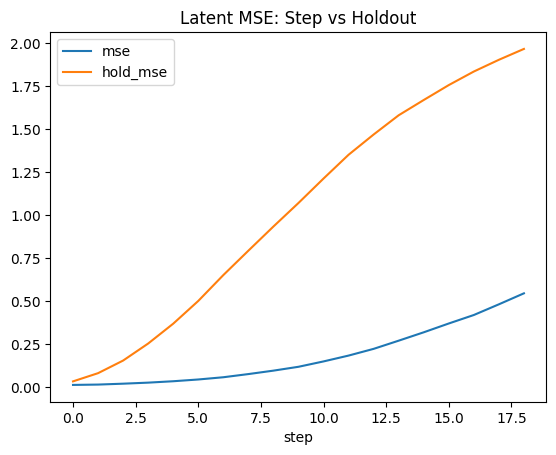

In [25]:
from wm.probe.runner import calculate_latent_mse_per_step, calculate_probe_mse_per_step

mse = calculate_latent_mse_per_step(zs, zts)  # (19,)
hold_mse = calculate_latent_mse_per_step(holds, zts)

z_decoded_mse = calculate_probe_mse_per_step(z_decodeds, gts)  # (T, 4)
z_decoded_mse_hold = calculate_probe_mse_per_step(hold_decodeds, gts)  # (T, 4)

latent_mse_df = pd.DataFrame(
    {
        "mse": mse,
        "hold_mse": hold_mse,
    },
    index=range(mse.shape[0]),  # step
)
latent_mse_df.index.name = "step"
display(latent_mse_df)

latent_mse_df.plot(
    y=["mse", "hold_mse"],
    kind="line",
    title="Latent MSE: Step vs Holdout",
)


<Axes: title={'center': 'Decoded probe MSE (hold)'}, xlabel='step'>

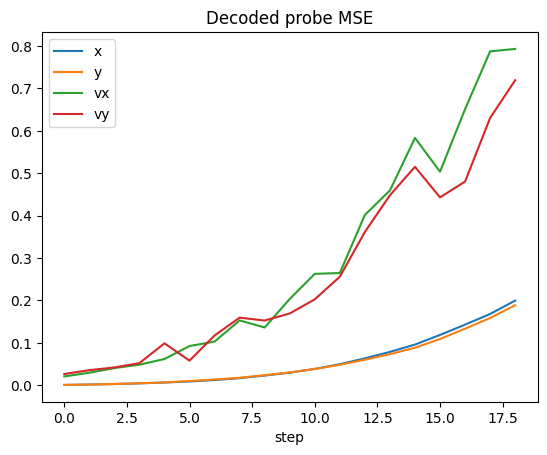

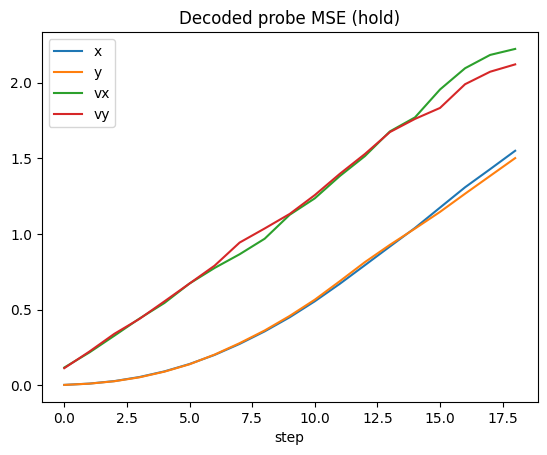

In [26]:
df_dec = pd.DataFrame(
    z_decoded_mse,
    index=range(z_decoded_mse.shape[0]),
    columns=["x", "y", "vx", "vy"],
)
df_dec.index.name = "step"
df_dec.plot(kind="line", title="Decoded probe MSE")

df_dec_hold = pd.DataFrame(
    z_decoded_mse_hold,
    index=range(z_decoded_mse_hold.shape[0]),
    columns=["x", "y", "vx", "vy"],
)
df_dec_hold.index.name = "step"
df_dec_hold.plot(kind="line", title="Decoded probe MSE (hold)")


In [27]:
z_shuffle, zt_shuffle, hold_shuffle, hold_decoded_shuffle, z_decoded_shuffle, gt_shuffle = rollout(
    nets, device, probe_gt_mean, probe_gt_std, shuffle_actions=True
)


Rollout: 100%|██████████| 100/100 [00:03<00:00, 27.84it/s]


<Axes: title={'center': 'Decoded Shuffle MSE'}>

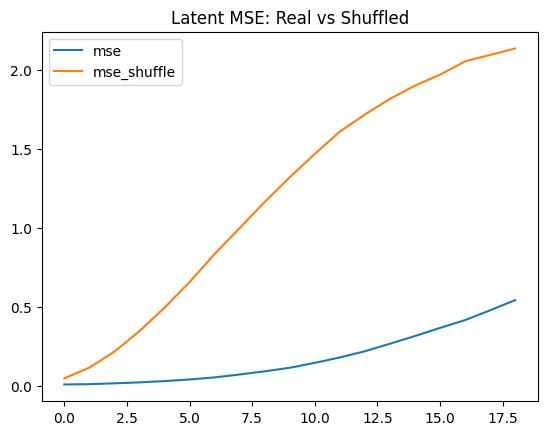

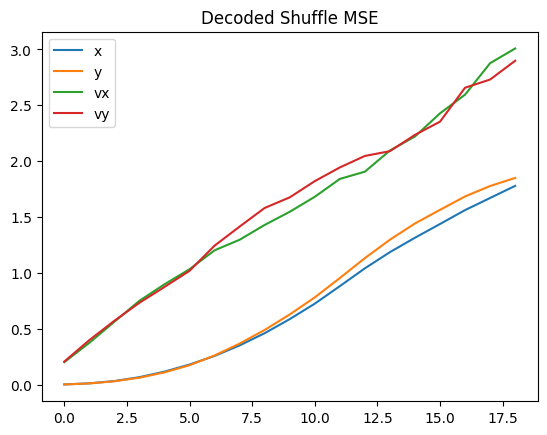

In [28]:
latent_mse_shuffle = calculate_latent_mse_per_step(z_shuffle, zt_shuffle)  # (19,)
hold_mse_shuffle = calculate_latent_mse_per_step(hold_shuffle, zt_shuffle)

z_decoded_mse_shuffle = calculate_probe_mse_per_step(z_decoded_shuffle, gt_shuffle)  # (T, 4)
z_decoded_mse_hold_shuffle = calculate_probe_mse_per_step(
    hold_decoded_shuffle, gt_shuffle
)  # (T, 4)

latent_mse_shuffle_df = pd.DataFrame(
    {
        "mse": mse,  # real actions, from the earlier cell
        "mse_shuffle": latent_mse_shuffle,
    },
    index=range(latent_mse_shuffle.shape[0]),
)

latent_mse_shuffle_df.plot(
    y=["mse", "mse_shuffle"],
    kind="line",
    title="Latent MSE: Real vs Shuffled",
)

decoded_mse_shuffle_df = pd.DataFrame(
    z_decoded_mse_shuffle,
    index=range(z_decoded_mse_shuffle.shape[0]),  # step
    columns=["x", "y", "vx", "vy"],
)
decoded_mse_shuffle_df.plot(
    y=["x", "y", "vx", "vy"],
    kind="line",
    title="Decoded Shuffle MSE",
)


,0
dim,
0,1.145
1,0.909
2,0.992
3,1.007
4,1.121
5,1.197
6,1.002
7,1.090
8,0.907


smallest var 0.8517168
0.9641689


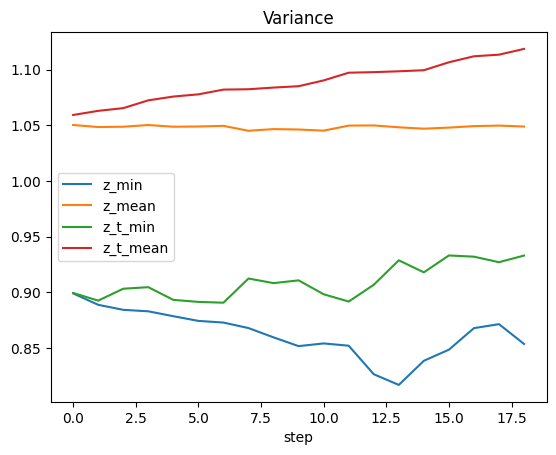

In [29]:
# gate 1
# z_hat / z_t is 0.872. this is a mild shrinkage of the rollout relative to the encoder

step_10_var = np.var(zs[:, 9, :], axis=0)  # (D,)

per_step_vars = np.var(zs, axis=0)  # (T, D)
per_step_vars_t = np.var(zts, axis=0)  # (T, D)

per_step_min_vars_df = pd.DataFrame(
    {
        "z_min": per_step_vars.min(axis=1),
        "z_mean": per_step_vars.mean(axis=1),
        "z_t_min": per_step_vars_t.min(axis=1),
        "z_t_mean": per_step_vars_t.mean(axis=1),
    },
    index=range(per_step_vars.shape[0]),  # step
)
per_step_min_vars_df.index.name = "step"
per_step_min_vars_df.plot(kind="line", title="Variance")

step_10_var_df = pd.DataFrame(
    step_10_var,
    index=range(step_10_var.shape[0]),  # dim
)
step_10_var_df.index.name = "dim"
display(step_10_var_df.style.format("{:.3f}").background_gradient(axis=None))

mean_var = np.mean(step_10_var, axis=0)

smallest_var = np.sort(step_10_var, axis=0)[0]

print("smallest var", smallest_var)

tgt_var = np.var(zts[:, 9, :], axis=0).mean()  # the same number, on z_target
ratio = mean_var / tgt_var

print(ratio)


shuffle / normal mse ratio 14.514212


<Axes: title={'center': 'Normal vs Holdout MSE'}, xlabel='step'>

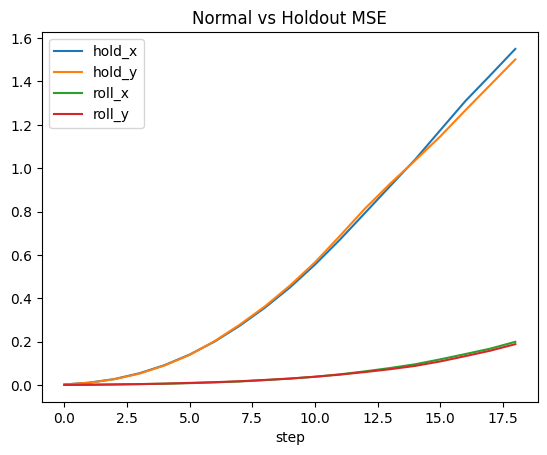

In [30]:
# gate 2
step_5_vx_mse = z_decoded_mse[4, 2]

step_5_vx_shuffle_mse = z_decoded_mse_shuffle[4, 2]

ratio = step_5_vx_shuffle_mse / step_5_vx_mse

print("shuffle / normal mse ratio", ratio)

# gate 3

mse_roll = calculate_probe_mse_per_step(z_decodeds, gts)
mse_hold = calculate_probe_mse_per_step(hold_decodeds, gts)

hold_df = pd.DataFrame(
    {
        "hold_x": mse_hold[:, 0],
        "hold_y": mse_hold[:, 1],
        "roll_x": mse_roll[:, 0],
        "roll_y": mse_roll[:, 1],
    },
    index=range(mse_hold.shape[0]),  # step
)
hold_df.index.name = "step"
hold_df.plot(kind="line", title="Normal vs Holdout MSE")


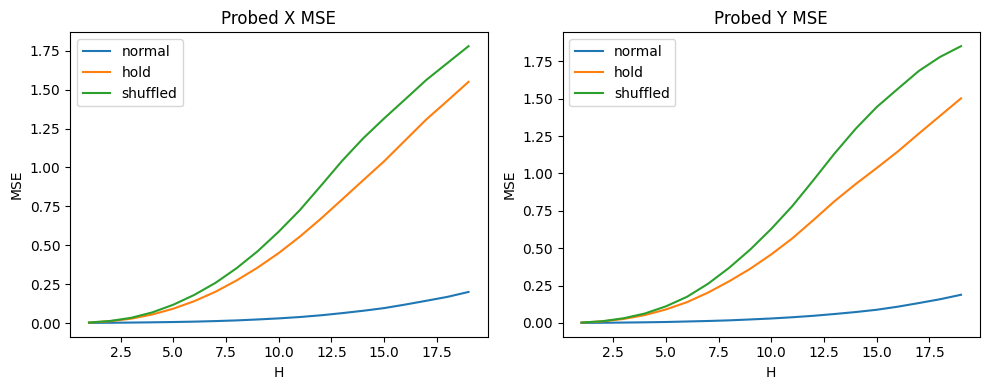

In [31]:
# all 3 drawn

mse_roll = calculate_probe_mse_per_step(z_decodeds, gts)
mse_hold = calculate_probe_mse_per_step(hold_decodeds, gts)
mse_shuffle = calculate_probe_mse_per_step(z_decoded_shuffle, gts)

fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharex=True)
for ax, dim, name in ((axes[0], 0, "X"), (axes[1], 1, "Y")):
    pd.DataFrame(
        {
            "normal": mse_roll[:, dim],
            "hold": mse_hold[:, dim],
            "shuffled": mse_shuffle[:, dim],
        },
        index=range(1, mse_roll.shape[0] + 1),
    ).plot(ax=ax, title=f"Probed {name} MSE")
    ax.set_xlabel("H")
    ax.set_ylabel("MSE")
fig.tight_layout()

[0.9077653  0.90607625 0.9013514  0.9069867  0.89827245 0.87116975
 0.87238556 0.82636136 0.854      0.8061526  0.7716695  0.79000366
 0.7028932  0.6931809  0.63058436 0.709529   0.64471567 0.5941353
 0.5989386 ]


<Axes: title={'center': 'R2 of VX MSE vs VX Variance'}>

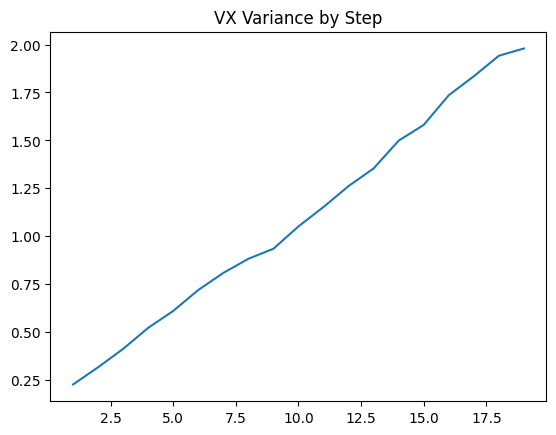

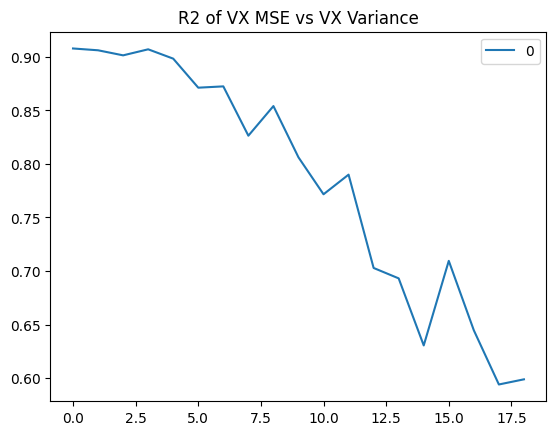

In [32]:
ev["gt_t"].shape
ev["t"][0:21]

vx = ev["gt_tp1"][:, 2]

var_by_step = pd.Series(vx).groupby(ev["t"]).var()

var_by_step.plot(kind="line", title="VX Variance by Step")

var_vx = np.array([ev["gt_tp1"][:, 2][ev["t"] == ti].var() for ti in np.unique(ev["t"])])
mse_vx = mse_roll[:, 2]
r2 = 1 - mse_vx / var_vx
print(r2)

r2_df = pd.DataFrame(
    r2,
    index=range(r2.shape[0]),
)
r2_df.plot(kind="line", title="R2 of VX MSE vs VX Variance")


<Axes: title={'center': 'Law Delta'}>

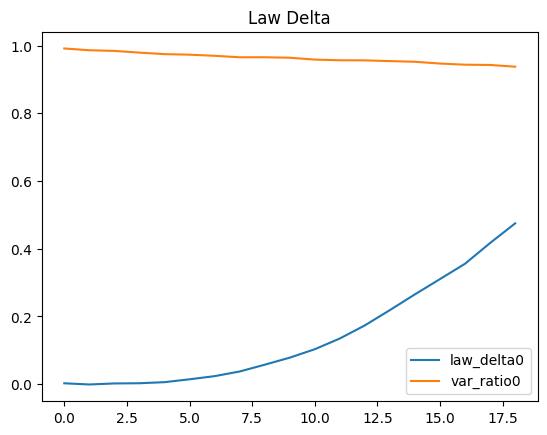

In [ ]:
z_hat_mse = calculate_latent_mse_per_step(zs, zts)  # (19,)
zt_var = calculate_per_dim_variance(zts)  # (19, 32)
z_hat_var = calculate_per_dim_variance(zs)  # (19, 32)

# if this is positive it means
law_total_var = z_hat_var.mean(axis=1) + z_hat_mse

law_delta = law_total_var - zt_var.mean(axis=1)

delta_ratio = law_delta / zt_var.mean(axis=1)

var_ratio = z_hat_var.mean(axis=1) / zt_var.mean(axis=1)

# var ratio -> 1 AND delta ratio -> 0.2 @ step 4
# this must mean MSE continues to rise at the same time as MSE
# the model is overconfident

law_delta_df = pd.concat(
    [
        pd.DataFrame(law_delta, index=range(law_delta.shape[0])).add_prefix("law_delta"),
        pd.DataFrame(var_ratio, index=range(var_ratio.shape[0])).add_prefix("var_ratio"),
    ],
    axis=1,
)
law_delta_df.plot(kind="line", title="Law Delta")

### Splitting `law_delta`: drift or over-reach?

`law_delta` is $\operatorname{Var}(\hat z) + \text{MSE} - \operatorname{Var}(z^*)$: how far the spread of the predictions sits above the hedge line $\operatorname{Var}(z^*) - \text{MSE}$. A positive value can come from two different failures. The split below is per latent dimension and per rollout step, with every variance and covariance taken across episodes, then averaged over the $D = 32$ dimensions.

Write the error as $e = z^* - \hat z$.

**1. The targets' variance.** Since $z^* = \hat z + e$,

$$
\operatorname{Var}(z^*) = \operatorname{Var}(\hat z) + \operatorname{Var}(e) + 2\operatorname{Cov}(\hat z, e)
$$

**2. The MSE.** The mean of a square is its variance plus its mean squared:

$$
\text{MSE} = \mathbb{E}[e^2] = \operatorname{Var}(e) + \big(\mathbb{E}[e]\big)^2 = \operatorname{Var}(e) + \text{bias}^2,
\qquad \text{bias} = \mathbb{E}[z^*] - \mathbb{E}[\hat z]
$$

**3. Substitute.** $\operatorname{Var}(e)$ cancels:

$$
\texttt{law\_delta} = \operatorname{Var}(\hat z) + \text{MSE} - \operatorname{Var}(z^*)
= \underbrace{\text{bias}^2}_{\text{drift}} \; \underbrace{-\, 2\operatorname{Cov}(\hat z, e)}_{\text{over-reach}}
$$

- **Drift**, $\text{bias}^2 \ge 0$: the whole rollout is shifted. It raises the MSE, so it lowers the hedge line, without changing $\operatorname{Var}(\hat z)$.
- **Over-reach**, $-2\operatorname{Cov}(\hat z, e)$: when $\hat z$ is high the truth tends to be lower, and vice versa. The predictions spread out more than the truth supports. (If it is negative, the predictions are over-shrunk instead.)

**4. The slope.** Regress $z^*$ on $\hat z$:

$$
b = \frac{\operatorname{Cov}(\hat z, z^*)}{\operatorname{Var}(\hat z)}
= \frac{\operatorname{Var}(\hat z) + \operatorname{Cov}(\hat z, e)}{\operatorname{Var}(\hat z)}
= 1 + \frac{\operatorname{Cov}(\hat z, e)}{\operatorname{Var}(\hat z)}
$$

so the over-reach term is the slope's shortfall from 1, scaled by the spread:

$$
-2\operatorname{Cov}(\hat z, e) = 2\,(1 - b)\,\operatorname{Var}(\hat z)
$$

$b = 1$: honest hedge. $b < 1$: the truth moves less than the predictions, overconfident. $b > 1$: over-shrunk. Drift does not change $b$. In the code, $b$ is pooled over dimensions: $\sum_j \operatorname{Cov}(\hat z_j, z^*_j) / \sum_j \operatorname{Var}(\hat z_j)$.

Both identities are exact for population variances (`np.var`, ddof = 0), so the cell below asserts them.

In [ ]:
# split law_delta into drift and over-reach, and the slope of z* on z_hat
# uses zs, zts (E, T, D) from the rollout cell and law_delta, z_hat_var from the cell above
# every mean is over episodes (axis 0) first, then over the D latent dims, as in law_delta

zs_c = zs - zs.mean(axis=0)  # (E, T, D) centred over episodes
zts_c = zts - zts.mean(axis=0)
err = zts - zs  # e = z* - z_hat
err_c = err - err.mean(axis=0)

# drift: the rollout's average sits away from the targets' average
bias2 = ((zs.mean(axis=0) - zts.mean(axis=0)) ** 2).mean(axis=1)  # (T,)
# over-reach: errors run against the predictions, -2 Cov(z_hat, e)
over_reach = -2 * (zs_c * err_c).mean(axis=0).mean(axis=1)  # (T,)
# slope of z* regressed on z_hat, pooled over dims: sum Cov(z_hat, z*) / sum Var(z_hat)
slope = (zs_c * zts_c).mean(axis=0).sum(axis=1) / (zs_c**2).mean(axis=0).sum(axis=1)  # (T,)

# the two pieces add back up to law_delta, and over-reach is the slope's shortfall scaled
assert np.allclose(bias2 + over_reach, law_delta, atol=1e-4)
assert np.allclose(over_reach, 2 * (1 - slope) * z_hat_var.mean(axis=1), atol=1e-4)

steps = np.arange(1, len(slope) + 1)  # column h is h + 1 steps ahead
fig, (ax_gap, ax_slope) = plt.subplots(1, 2, figsize=(11, 4))
ax_gap.plot(steps, law_delta, color="k", label="law_delta (total gap)")
ax_gap.plot(steps, over_reach, color="C3", ls="--", label="over-reach: -2 Cov(z_hat, e)")
ax_gap.plot(steps, bias2, color="C0", label="drift: bias^2")
ax_slope.plot(steps, slope, color="C3", label="slope of z* on z_hat")
ax_slope.axhline(1, color="grey", lw=1, ls=":")
for ax in (ax_gap, ax_slope):
    ax.axvline(5, color="grey", lw=1, ls="--")  # training horizon
    ax.set_xlabel("rollout step")
    ax.legend()
ax_gap.set_title("Gap above the hedge line, split")
ax_slope.set_title("Slope of z* on z_hat")
fig.tight_layout()

display(
    pd.DataFrame(
        {"law_delta": law_delta, "bias2": bias2, "over_reach": over_reach, "slope": slope},
        index=pd.Index(steps, name="step"),
    ).round(4)
)

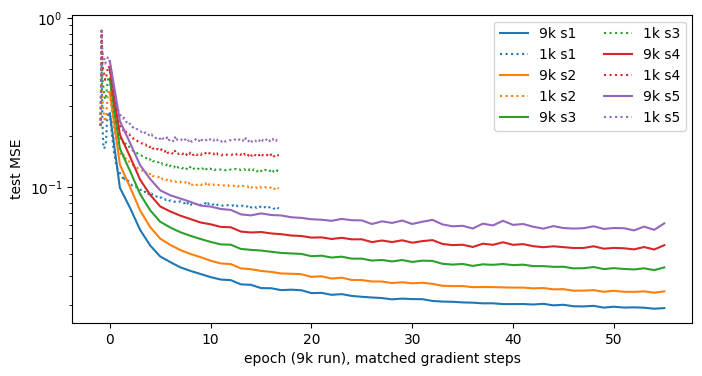

In [34]:
from wm.env.paths import run_paths

new = pd.read_json(run_paths("20261029-125202").log, lines=True)
old = pd.read_json(run_paths("20261028-h5-1k").log, lines=True)
old["equiv_new_epoch"] = (old["epoch"] + 1) / 11.25 - 1  # matched gradient steps

fig, ax = plt.subplots(figsize=(8, 4))
for s in range(5):
    ax.plot(new["epoch"], new["test_mse_losses"].str[s], color=f"C{s}", label=f"9k s{s + 1}")
    ax.plot(
        old["equiv_new_epoch"],
        old["test_mse_losses"].str[s],
        color=f"C{s}",
        ls=":",
        label=f"1k s{s + 1}",
    )
ax.set_xlabel("epoch (9k run), matched gradient steps")
ax.set_ylabel("test MSE")
ax.set_yscale("log")
ax.legend(ncol=2)

z_hat r2: 0.9798741
min_ztvar: 0.9183393
min_z_hat_var: 0.90543973
x: mse=0.0004187  r2=0.9996
y: mse=0.0004308  r2=0.9996
vx: mse=0.08502  r2=0.9148
vy: mse=0.07928  r2=0.9195
Percent movement in unit direction x: 25.04%
Percent movement in unit direction y: 31.53%
Percent movement in unit direction vx: 9.44%
Percent movement in unit direction vy: 10.36%
Error in x direction: 0.56%
Error in y direction: 0.49%
Error in vx direction: 2.36%
Error in vy direction: 2.04%
Fraction of error in projection: 28.82%
Variance in subspace: 60.41%
Relative error overall: 2.01%
Relative error in state subspace: 0.96%
Relative error outside: 3.62%
PCs for 50%: 2
PCs for 90%: 8
top t projected on unit directions


array([[ 0.45, -0.93,  0.2 , -0.41],
       [ 0.88,  0.35,  0.52,  0.36],
       [-0.03,  0.01, -0.1 , -0.05],
       [ 0.07, -0.03,  0.24, -0.15],
       [-0.  ,  0.01,  0.01, -0.1 ],
       [-0.08,  0.03, -0.33,  0.52],
       [-0.03, -0.02, -0.19, -0.26],
       [ 0.05, -0.01, -0.49,  0.18]])

top t projected on orthogonal directions


array([0.99, 0.99, 0.02, 0.08, 0.02, 0.44, 0.15, 0.4 ])

cosines between x, y, vx, vy


array([[ 1.  , -0.12,  0.56,  0.08],
       [-0.12,  1.  , -0.02,  0.51],
       [ 0.56, -0.02,  1.  , -0.03],
       [ 0.08,  0.51, -0.03,  1.  ]], dtype=float32)

x: probe r2=0.9995  end-to-end r2=0.9985  gap=0.0010
y: probe r2=0.9995  end-to-end r2=0.9985  gap=0.0010
vx: probe r2=0.9127  end-to-end r2=0.9239  gap=-0.0111
vy: probe r2=0.9152  end-to-end r2=0.9205  gap=-0.0054


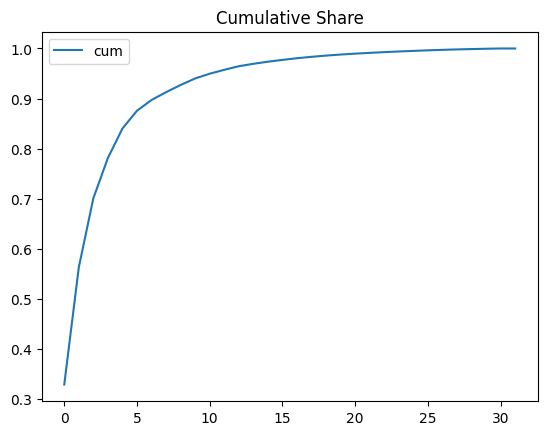

In [35]:
# one-step latent audit: every array here is at t+1, so prediction and target line up
# audit_ names keep this cell from overwriting the rollout results in zs, zts and mse
audit_z_hat = ev["z_hat"]  # (N, 32)
audit_zt = ev["z_target"]  # (N, 32)
audit_gt = ev["gt_tp1"]  # (N, 4)
audit_z_hat_var = np.var(audit_z_hat, axis=0)  # (32,)
audit_zt_var = np.var(audit_zt, axis=0)  # (32,)

residual = audit_z_hat - audit_zt  # (N, 32)
audit_mse = np.mean(residual**2)  # scalar
audit_r2 = 1 - audit_mse / audit_zt_var.mean()  # scalar

print("z_hat r2:", audit_r2)
print("min_ztvar:", np.min(audit_zt_var))
print("min_z_hat_var:", np.min(audit_z_hat_var))

names = ["x", "y", "vx", "vy"]

# encoder representation of the current state: (t-1, t) -> t
gt_now = ev["gt_t"]
now_mse = ((ev["z_decoded"] - gt_now) ** 2).mean(axis=0)
now_r2 = 1 - now_mse / gt_now.var(axis=0)
for n, m, r in zip(names, now_mse, now_r2):
    print(f"{n}: mse={m:.4g}  r2={r:.4f}")

# Cov(z, gt) gives the directions where each state variable shows up in z. the ridge beta
# gives decoder weights, which also cancel nuisance, so it misses where the state sits
zt_centered = audit_zt - audit_zt.mean(axis=0)
gt_centered = audit_gt - audit_gt.mean(axis=0)
state_directions = zt_centered.T @ gt_centered / (len(audit_zt) - 1)  # (32, 4)
# divide dirs by magnitude of dirs
unit_directions = state_directions / np.linalg.norm(state_directions, axis=0, keepdims=True)

zt_cov = np.cov(audit_zt, rowvar=False)

total_var = np.trace(zt_cov)

# these directions aren't orthogonal, so the shares overlap and don't sum to the subspace share
for i in range(unit_directions.shape[1]):
    unit_direction = unit_directions[:, i]
    variance_in_direction = unit_direction.T @ zt_cov @ unit_direction
    print(f"Percent movement in unit direction {names[i]}: {variance_in_direction / total_var:.2%}")

for i in range(unit_directions.shape[1]):
    unit_direction = unit_directions[:, i]
    s = audit_zt @ unit_direction  # projection in target direction
    r = residual @ unit_direction  # error in target direction
    error_ratio = np.mean(r**2) / np.var(s)  # if ~0 there is little error in this direction
    print(f"Error in {names[i]} direction: {error_ratio:.2%}")

q = np.linalg.qr(unit_directions)[0]  # (32, 4)

# split each residual into its part inside the state subspace and the rest
residual_proj = (residual @ q) @ q.T

err_total = (residual**2).sum(axis=1)  # per sample
err_in_projection = (residual_proj**2).sum(axis=1)
err_out_projection = err_total - err_in_projection

frac_in = err_in_projection.sum() / err_total.sum()
in_var = np.trace(q.T @ zt_cov @ q)

# if error were spread like the variance, these two shares would match
print(f"Fraction of error in projection: {frac_in:.2%}")
print(f"Variance in subspace: {in_var / total_var:.2%}")

print(f"Relative error overall: {err_total.mean() / total_var:.2%}")
print(f"Relative error in state subspace: {err_in_projection.mean() / in_var:.2%}")
print(f"Relative error outside: {err_out_projection.mean() / (total_var - in_var):.2%}")

evals, evecs = np.linalg.eigh(zt_cov)
evals, evecs = evals[::-1], evecs[:, ::-1]  # largest first
share = evals / evals.sum()
# cumulative share
cum = np.cumsum(share)

print("PCs for 50%:", int(np.searchsorted(cum, 0.50) + 1))
print("PCs for 90%:", int(np.searchsorted(cum, 0.90) + 1))

cum_df = pd.DataFrame(
    {
        "cum": cum,
    },
    index=range(len(evals)),
)

cum_df.plot(kind="line", title="Cumulative Share")

top = evecs[:, :8]  # top 8 PCs as columns (32,8)
print("top t projected on unit directions")
display(np.round(top.T @ unit_directions, 2))  # cosine of each PC with x, y, vx, vy
print("top t projected on orthogonal directions")
display(np.round(((top.T @ q) ** 2).sum(axis=1), 2))  # share of each PC inside the state subspace
print("cosines between x, y, vx, vy")
display(np.round(unit_directions.T @ unit_directions, 2))  # 4x4 cosines between x, y, vx, vy

target_r2 = 1 - ((ev["z_target_decoded"] - audit_gt) ** 2).mean(axis=0) / audit_gt.var(axis=0)
hat_r2 = 1 - ((ev["z_hat_decoded"] - audit_gt) ** 2).mean(axis=0) / audit_gt.var(axis=0)
for n, pr, r in zip(names, target_r2, hat_r2):
    print(f"{n}: probe r2={pr:.4f}  end-to-end r2={r:.4f}  gap={pr - r:.4f}")

In [36]:
# is the variance outside the linear state span nuisance, or just curved state?
#
# the audit above finds about 40% of latent variance outside the Cov(z, y) subspace, and
# PCs 3-5 barely overlap it. that subspace is flat, so it would also miss state that the
# encoder stores nonlinearly (e.g. x**2). the frames are a deterministic render of the state
# with no noise or distractors, so there should be little else for the encoder to store
#
# test: predict each latent PC from the true state, with a linear fit and with a small MLP
# - linear fails, MLP succeeds => the PC is a nonlinear function of state, not nuisance
# - both fail => the PC holds something that isn't in the state
#
# everything is scored on held-out episodes. rows from one episode are autocorrelated, so
# splitting rows rather than episodes would flatter the MLP
# the control shuffles the state across episodes, which should explain nothing. if it scores
# well the test is leaking
#
# run 20261029-125202, best.pth, one-step targets:
#   PC    share  linear   mlp
#   1     0.329   0.876  0.999
#   2     0.233   0.903  0.998
#   3     0.137  -0.013  0.997
#   4     0.080   0.027  0.996
#   5     0.059   0.007  0.995
#   all 32 dims:  0.528  0.994
#   control PC1-5: all negative
#
# conclusion: PCs 3-5 are state. the latent is the 4-D state on a curved surface in 32-D, so
# the error "outside the subspace" above is error in the nonlinear part of the state code.
# there is almost no nuisance to remove, so no case for a smaller latent or a covariance term
#
# what this means for the planner: use the MLP probe for the cost, since ridge only reads the
# flat part of a curved code. if rollouts leave the surface the MLP probe is extrapolating, so
# check the calibration gap
#
# this only covers the target latents at one step, not rollouts


def state_check_r2(pred, y):
    return 1 - ((pred - y) ** 2).mean(axis=0) / y.var(axis=0)


def state_check_linear(x, y, fit, held):
    fit_x = np.c_[x[fit], np.ones(len(fit))]  # column of ones for the bias
    held_x = np.c_[x[held], np.ones(len(held))]
    weights = np.linalg.lstsq(fit_x, y[fit], rcond=None)[0]
    return held_x @ weights


def state_check_mlp(x, y, fit, held, epochs=3000, width=256):
    torch.manual_seed(0)
    x_mean, x_std = x[fit].mean(axis=0), x[fit].std(axis=0)
    y_mean, y_std = y[fit].mean(axis=0), y[fit].std(axis=0)
    fit_x = torch.tensor((x[fit] - x_mean) / x_std, dtype=torch.float32, device=device)
    fit_y = torch.tensor((y[fit] - y_mean) / y_std, dtype=torch.float32, device=device)
    held_x = torch.tensor((x[held] - x_mean) / x_std, dtype=torch.float32, device=device)

    net = torch.nn.Sequential(
        torch.nn.Linear(x.shape[1], width),
        torch.nn.GELU(),
        torch.nn.Linear(width, width),
        torch.nn.GELU(),
        torch.nn.Linear(width, width),
        torch.nn.GELU(),
        torch.nn.Linear(width, y.shape[1]),
    ).to(device)
    optimizer = torch.optim.AdamW(net.parameters(), lr=2e-3, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, epochs)
    for _ in range(epochs):
        optimizer.zero_grad()
        torch.nn.functional.mse_loss(net(fit_x), fit_y).backward()
        optimizer.step()
        scheduler.step()

    with torch.no_grad():
        return net(held_x).cpu().numpy() * y_std + y_mean


# use the arrays directly so this cell runs without the audit cell above
check_zt = ev["z_target"]  # (N, 32), encodes (t, t+1)
check_state = ev["gt_tp1"]  # (N, 4), so the state at t+1 lines up with the target

# test_loader isn't shuffled, so rows are in episode order
n_rows_per_episode = 19
n_check_episodes = len(check_zt) // n_rows_per_episode
check_rng = np.random.default_rng(0)
check_episodes = check_rng.permutation(n_check_episodes)
n_fit_episodes = int(0.8 * n_check_episodes)


def episode_rows(episodes):
    return (episodes[:, None] * n_rows_per_episode + np.arange(n_rows_per_episode)).ravel()


fit_rows = episode_rows(check_episodes[:n_fit_episodes])
held_rows = episode_rows(check_episodes[n_fit_episodes:])

# the PCA only sees the fit episodes
check_mean = check_zt[fit_rows].mean(axis=0)
check_evals, check_evecs = np.linalg.eigh(np.cov(check_zt[fit_rows], rowvar=False))
check_evals, check_evecs = check_evals[::-1], check_evecs[:, ::-1]  # largest first
check_share = check_evals / check_evals.sum()

n_check_pcs = 12
check_pcs = (check_zt - check_mean) @ check_evecs[:, :n_check_pcs]  # (N, 12)

linear_r2 = state_check_r2(
    state_check_linear(check_state, check_pcs, fit_rows, held_rows), check_pcs[held_rows]
)
mlp_r2 = state_check_r2(
    state_check_mlp(check_state, check_pcs, fit_rows, held_rows), check_pcs[held_rows]
)

display(
    pd.DataFrame(
        {"share": check_share[:n_check_pcs], "linear r2": linear_r2, "mlp r2": mlp_r2},
        index=pd.RangeIndex(1, n_check_pcs + 1, name="PC"),
    ).round(3)
)


def variance_explained(pred):
    held_zt = check_zt[held_rows]
    return 1 - ((pred - held_zt) ** 2).sum() / ((held_zt - held_zt.mean(axis=0)) ** 2).sum()


print(
    "All latent variance, linear:",
    round(
        float(variance_explained(state_check_linear(check_state, check_zt, fit_rows, held_rows))), 4
    ),
)
print(
    "All latent variance, mlp:",
    round(
        float(variance_explained(state_check_mlp(check_state, check_zt, fit_rows, held_rows))), 4
    ),
)

# control: give each episode another episode's state
shuffled_episodes = episode_rows(check_rng.permutation(n_check_episodes))
control_r2 = state_check_r2(
    state_check_mlp(check_state[shuffled_episodes], check_pcs, fit_rows, held_rows),
    check_pcs[held_rows],
)
print("Control, shuffled state, PC1-5:", np.round(control_r2[:5], 3))

,share,linear r2,mlp r2
PC,,,
1,0.329,0.876,0.999
2,0.233,0.903,0.998
3,0.137,-0.013,0.997
4,0.080,0.027,0.996
5,0.059,0.007,0.995
6,0.036,0.256,0.991
7,0.022,0.115,0.990
8,0.016,0.312,0.987
9,0.014,0.237,0.984


All latent variance, linear: 0.5282
All latent variance, mlp: 0.9939
Control, shuffled state, PC1-5: [-0.445 -0.451 -0.403 -0.467 -0.429]
